<a href="https://colab.research.google.com/github/git-konick/Python_TSU_lec9/blob/main/Lecture_9_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лекция 9: Парсинг форматов разметки в Computer Vision

**Дисциплина:** Базовый курс python

**Связь с прошлым занятием:** На 8-м занятии мы научились работать с "сырыми" пикселями (матрицами). Сегодня мы добавляем смысл: учим машину понимать, *где* и *что* находится на изображении.

---








## 1. Введение: Проблема "Сырых Данных"

В задачах обучения с учителем (Supervised Learning) модели недостаточно просто картинки. Ей нужна **функция потерь (Loss Function)**, которая сравнивает предсказание с "истиной" (Ground Truth).

**Аннотация (разметка)** — это структурированные метаданные, описывающие содержание изображения.

### Ключевые термины:
1.  **Bounding Box (BBox):** Прямоугольная рамка, ограничивающая объект. Самый базовый примитив.
2.  **Класс (Категория):** Семантический ярлык объекта (например, "кошка", "автомобиль").
3.  **Нормализация:** Приведение координат к диапазону [0, 1] относительно размеров изображения.
4.  **Инстанс (Instance):** Конкретный объект. Если на фото 3 собаки, это 3 разных инстанса одного класса.

> **Аналогия:**
> Изображение — это холст. Аннотации — это экспликация в музее или чертеж. Без чертежа (аннотаций) мы видим просто набор кирпичей (пикселей), но не понимаем, где несущая стена, а где окно.

---

## 2. Обзор основных форматов ("Большая тройка")

В индустрии исторически сложились три стандарта. Умение конвертировать их между собой — обязательный навык ML-инженера.

### 2.1. COCO (Common Objects in Context)
*Фактический стандарт для сложных задач (сегментация, позы).*

*   **Формат:** Один огромный JSON файл на весь датасет.
*   **Структура:** Реляционная база данных.
    *   `images`: список файлов и их размеры (`width`, `height`).
    *   `categories`: справочник классов (`id`, `name`).
    *   `annotations`: сами объекты. Связь через `image_id` и `category_id`.
*   **Координаты:** Абсолютные пиксели: `[x_min, y_min, width, height]`.
    *   *Важно:* `x_min, y_min` — это верхний левый угол.

### 2.2. YOLO (You Only Look Once)
*Стандарт для детекции в реальном времени. Максимальная простота.*

*   **Формат:** Текстовый файл `.txt` для *каждого* изображения.
*   **Структура:** Одна строка на объект.
    `class_id x_center y_center width height`
*   **Координаты:** Нормализованные (от 0 до 1).
    *   Центр объекта + ширина и высота, деленные на размеры картинки.

### 2.3. Pascal VOC
*Наследие 2000-х (эпоха SVM и ранних CNN), но до сих пор встречается.*

*   **Формат:** Файл `.xml` на каждое изображение.
*   **Структура:** Иерархическое дерево тегов.
    ```xml
    <object>
      <name>dog</name>
      <bndbox>
        <xmin>48</xmin><ymin>240</ymin>
        <xmax>195</xmax><ymax>371</ymax>
      </bndbox>
    </object>
    ```

---

## 3. Практический блок

Ниже представлен скрипт, который можно запустить в Jupyter/Colab. Он эмулирует датасет (чтобы не качать гигабайты), парсит его, рисует боксы и конвертирует форматы.

### Скрипт: Парсер и Конвертер

Демо-датасет создан: изображение и COCO JSON.

--- Начало конвертации в YOLO ---
Image ID 1: dog
COCO:  [x:100, y:150, w:200, h:250]
YOLO:  0 0.312500 0.572917 0.312500 0.520833


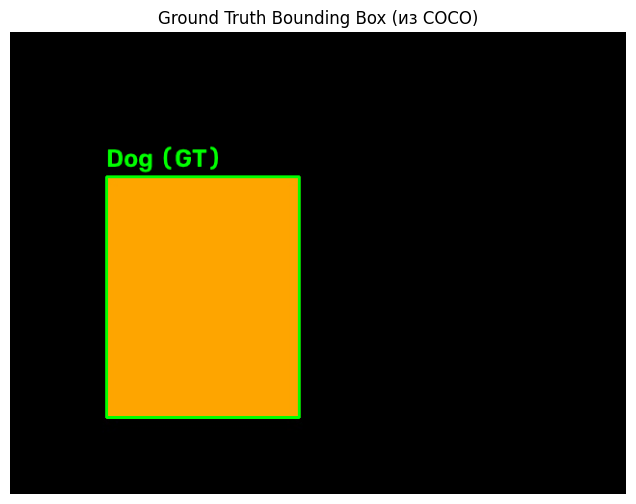

In [28]:
import json
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

# =====================================================================
# ШАГ 1: Подготовка "Игрушечного" датасета (Mock Data)
# =====================================================================
# Создадим папку, если её нет
os.makedirs("dataset_demo", exist_ok=True)

# 1. Создадим синтетическое изображение (черный фон 640x480)
# Это эмулирует выход библиотек PIL/OpenCV с прошлого занятия
img_width, img_height = 640, 480
dummy_image = np.zeros((img_height, img_width, 3), dtype=np.uint8)

# Рисуем условную "собаку" (оранжевый прямоугольник)
# В реальности здесь были бы пиксели собаки
cv2.rectangle(dummy_image, (100, 150), (300, 400), (0, 165, 255), -1) # BGR Orange
cv2.imwrite("dataset_demo/dog_01.jpg", dummy_image)

# 2. Создадим файл аннотации в формате COCO (JSON)
coco_data = {
    "images": [
        {"id": 1, "file_name": "dog_01.jpg", "width": img_width, "height": img_height}
    ],
    "annotations": [
        # COCO format: [x_min, y_min, width, height]
        # Собака: x=100, y=150, w=200, h=250
        {"id": 1, "image_id": 1, "category_id": 1, "bbox": [100, 150, 200, 250], "area": 50000, "iscrowd": 0}
    ],
    "categories": [
        {"id": 1, "name": "dog", "supercategory": "animal"}
    ]
}

with open("dataset_demo/annotations.json", "w") as f:
    json.dump(coco_data, f)

print("Демо-датасет создан: изображение и COCO JSON.")

# =====================================================================
# ШАГ 2: Функция парсинга COCO
# =====================================================================
def load_coco(json_path):
    with open(json_path, 'r') as f:
        data = json.load(f)
    return data

# =====================================================================
# ШАГ 3: Конвертер COCO -> YOLO
# =====================================================================
def convert_coco_to_yolo(coco_data, output_dir="yolo_labels"):
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    # Создаем словарь для быстрого поиска размеров изображения по ID
    # Это критически важно, так как в COCO координаты абсолютные,
    # а в YOLO нужны относительные.
    img_dict = {img['id']: img for img in coco_data['images']}
    cat_dict = {cat['id']: cat['name'] for cat in coco_data['categories']}

    print(f"\n--- Начало конвертации в YOLO ---")

    for ann in coco_data['annotations']:
        img_id = ann['image_id']
        img_info = img_dict[img_id]

        W, H = img_info['width'], img_info['height']

        # Извлекаем COCO bbox: [x_top_left, y_top_left, width, height]
        x, y, w, h = ann['bbox']

        # Математика конвертации в YOLO:
        # 1. Находим центр в абсолютных координатах
        x_center_abs = x + w / 2
        y_center_abs = y + h / 2

        # 2. Нормализуем (делим на размер картинки)
        x_center = x_center_abs / W
        y_center = y_center_abs / H
        norm_w = w / W
        norm_h = h / H

        # YOLO class id обычно начинается с 0. В COCO часто с 1.
        # Для примера возьмем category_id - 1 (или оставим как есть, зависит от задачи)
        class_id = ann['category_id'] - 1

        # Формируем строку: <class_id> <x_center> <y_center> <width> <height>
        yolo_line = f"{class_id} {x_center:.6f} {y_center:.6f} {norm_w:.6f} {norm_h:.6f}"

        print(f"Image ID {img_id}: {cat_dict[ann['category_id']]}")
        print(f"COCO:  [x:{x}, y:{y}, w:{w}, h:{h}]")
        print(f"YOLO:  {yolo_line}")

        # Сохраняем в файл с тем же именем, что и картинка, но расширением .txt
        img_filename = img_info['file_name']
        txt_filename = os.path.splitext(img_filename)[0] + ".txt"
        txt_path = os.path.join(output_dir, txt_filename)

        with open(txt_path, 'a') as f:
            f.write(yolo_line + "\n")

# =====================================================================
# ШАГ 4: Визуализация (Проверка)
# =====================================================================
def visualize_annotations(image_path, coco_data):
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Помним про разницу каналов!

    for ann in coco_data['annotations']:
        x, y, w, h = map(int, ann['bbox'])
        # Рисуем рамку (Зеленый цвет)
        cv2.rectangle(img_rgb, (x, y), (x+w, y+h), (0, 255, 0), 2)
        # Подпись
        cv2.putText(img_rgb, "Dog (GT)", (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)

    plt.figure(figsize=(8, 6))
    plt.imshow(img_rgb)
    plt.title("Ground Truth Bounding Box (из COCO)")
    plt.axis('off')
    plt.show()

# Запуск
data = load_coco("dataset_demo/annotations.json")
convert_coco_to_yolo(data)
visualize_annotations("dataset_demo/dog_01.jpg", data)

### Разбор кода для студентов:
1.  **Словари (`dict`):** Мы используем `img_dict`, чтобы мгновенно находить размеры изображения (`width`, `height`). В больших файлах линейный поиск занял бы вечность.
2.  **Центр объекта:** Обратите внимание на формулу `x + w / 2`. Частая ошибка новичков — передавать в YOLO верхний левый угол.
3.  **Нормализация:** Деление на `W` и `H` делает модель инвариантной к разрешению. Если мы сожмем картинку в 10 раз, координаты в YOLO не изменятся.

---

## 4. Глубокое погружение: Нюансы и подводные камни

Для магистрантов важно понимать не только "как", но и "почему возникают ошибки".

### 1. Системы координат
В изображениях (и COCO, и VOC) начало координат — **левый верхний угол**.
*   Ось X идет вправо.
*   Ось Y идет **вниз**.
*   *Следствие:* При аугментации (например, вертикальном флипе) формула изменения координат будет $y_{new} = H - (y_{old} + h)$.

### 2. Проблема "Пустых" изображений
В формате YOLO, если на картинке нет объектов, мы просто не создаем `.txt` файл (или создаем пустой). В COCO изображение без аннотаций все равно должно присутствовать в списке `images`, иначе скрипт обучения может выдать ошибку при чтении метаданных.

### 3. Инструментарий
Не пишите парсеры для продакшена с нуля, если можно использовать библиотеки, но писать их *учебные* версии полезно.
*   **pycocotools:** Стандарт де-факто для работы с COCO API.
*   **FiftyOne:** Мощный инструмент для визуализации и анализа датасетов.
*   **Label Studio / CVAT:** Программы для самой разметки. Умеют экспорт во все форматы.

---


## 5. Задание для самостоятельной работы (Базовое)

**Цель:** Закрепить навык конвертации данных для подготовки датасета под конкретную модель.

### Задание 1: Парсинг
Напишите скрипт, который читает JSON-файл (реальный или сгенерированный выше) и выводит статистику:
1.  Количество изображений.
2.  Количество объектов каждого класса (например: "собак - 5, кошек - 2").
3.  Средний размер бокса (в пикселях).

### Задание 2: Конвертер (Основное)
Реализуйте класс `DatasetConverter`.
*   **Вход:** Путь к JSON файлу формата COCO.
*   **Задача:** Извлечь боксы только для заданного класса (например, `"dog"`).
*   **Выход:** Сохранить метки в файлы формата YOLO в отдельную папку.
*   **Усложнение:** Игнорировать боксы, площадь которых меньше 1% от площади изображения (фильтрация шума).

---

## 6. Дополнительные задания для самопроверки (Вариативные)

Чтобы проверить понимание глубже, выполните одно из следующих заданий.

### Вариант А: "Обратный ход" (YOLO -> COCO)
Представьте, что вы разметили данные в LabelImg (формат YOLO) и хотите обучить модель Mask R-CNN (требует COCO).
1.  Создайте фиктивные `.txt` файлы.
2.  Напишите скрипт, который собирает их в один `annotation.json`.
3.  *Подсказка:* Вам понадобится заново присвоить уникальные `id` каждому объекту и создать список `categories`.

### Вариант Б: "Парсер Старой Школы" (XML -> YOLO)
Вам достался датасет 2010 года в формате Pascal VOC.
1.  Используйте библиотеку `xml.etree.ElementTree`.
2.  Распарсите структуру `<annotation><object><bndbox>`.
3.  Переведите координаты `xmin, ymin, xmax, ymax` в формат YOLO.
    *   *Формула:* $Width = x_{max} - x_{min}$.

### Вариант В: "Аугментация меток" (Hard Mode)
Вы решили расширить датасет, отразив все изображения по горизонтали (Flip).
1.  Напишите функцию, которая принимает аннотацию COCO `[x, y, w, h]` и ширину изображения `W`.
2.  Верните новые координаты бокса после горизонтального отражения.
    *   *Подсказка:* $x_{new} = W - (x_{old} + w)$. $y$ не меняется.



---

## 8. Чек-лист

1.  [ ] **Понимаю разницу:** COCO — это один JSON и абсолютные координаты. YOLO — много TXT и нормализованные центры.
2.  [ ] **Знаю формулу центра:** $x_{center} = x_{top\_left} + width / 2$.
3.  [ ] **Проверяю данные:** Если рамка вылезает за пределы картинки, значит при конвертации или разметке допущена ошибка (клиппинг координат).
4.  [ ] **Соблюдаю цвета:** Если рисую боксы через OpenCV, помню про BGR, если через Matplotlib — конвертирую в RGB.

### Рекомендуемые материалы для чтения:
1.  Документация `pycocotools` на GitHub.
2.  Статья "Data-Centric AI" (введение в важность качества разметки).
3.  Официальная документация формата Ultralytics YOLO (современный стандарт).

Ниже — блок который логично вставить после разбора COCO/YOLO/VOC. Он показывает следующий шаг пайплайна компьютерного зрения: **разметка → подготовка изображения → инференс модели через ONNX**.

---

# Дополнительный блок к лекции 9  
## От аннотаций к инференсу: ONNX-модели и экспорт из PyTorch

---

## 1. Зачем говорить об ONNX в теме аннотаций?

На прошлом этапе мы разобрали, как хранить и конвертировать разметку:

- **COCO** — удобен для сложных датасетов, сегментации, оценки качества.
- **YOLO** — удобен для детекции и обучения быстрых моделей.
- **Pascal VOC** — старый, но до сих пор встречающийся XML-формат.

Но в реальных проектах после подготовки данных обычно следует этап:

```text
Изображение + аннотация
        ↓
Предобработка
        ↓
Модель
        ↓
Предсказание
        ↓
Сохранение результата в нужном формате
```

И здесь возникает вопрос: **в каком формате хранить и запускать саму модель?**

Если модель обучена в PyTorch, её можно сохранить как `.pt` или `.pth`. Но для продакшена, ускоренного инференса, кроссплатформенного запуска и оптимизации часто используют **ONNX**.

---

## 2. Что такое ONNX?

**ONNX** — *Open Neural Network Exchange* — открытый формат представления нейросетевых моделей.

Он позволяет сохранить модель в виде стандартизированного вычислительного графа, который затем может быть запущен в разных средах:

- Python;
- C++;
- JavaScript;
- mobile-платформах;
- edge-устройствах;
- серверах инференса.

Фактически:

```text
PyTorch-модель → ONNX-файл → ONNX Runtime / TensorRT / OpenVINO / другой runtime
```

### Ключевые идеи

| Термин | Пояснение |
|---|---|
| **ONNX-граф** | Описание операций модели: входы, выходы, слои, веса |
| **opset** | Версия набора операторов ONNX |
| **ONNX Runtime** | Библиотека для запуска и оптимизации ONNX-моделей |
| **dynamic axes** | Возможность принимать входные данные с изменяющимися размерами, например, разным `batch_size` |
| **execution provider** | Бэкенд исполнения: CPU, CUDA, TensorRT и др. |
| **metadata** | Дополнительная информация: классы, версия датасета, нормализация и т.д. |

---




























































## 3. Аналогия

Можно представить процесс так:

- **Аннотации COCO/YOLO** — это техническое задание: где и какой объект находится.
- **Нейросеть** — это эксперт, который умеет находить или классифицировать объекты.
- **ONNX** — это универсальный исполняемый файл этого эксперта, который можно запустить на разных системах без повторной сборки всей лаборатории.

Или короче:

> **PyTorch удобен для экспериментов и обучения. ONNX часто удобнее для инференса и деплоя.**

---

## 4. Практический пример в Google Colab / Jupyter

Ниже приведён готовый демонстрационный блок. Он показывает:

1. Создание лёгкой PyTorch-модели.
2. Экспорт модели в ONNX.
3. Проверку ONNX-графа.
4. Запуск через ONNX Runtime.
5. Сравнение выходов PyTorch и ONNX.
6. Использование ONNX-модели для обработки кропа, полученного по COCO-аннотации.

---

## 5. Установка библиотек

В Colab обычно уже есть `torch` и `torchvision`, но `onnx` и `onnxruntime` может понадобиться установить отдельно.

---

In [3]:
!pip install -q onnx onnxruntime

# Если вдруг нет OpenCV:
# !pip install -q opencv-python-headless


## 6. Импорт библиотек


In [29]:
import os
import json
import time

import numpy as np
import matplotlib.pyplot as plt
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F

import onnx
import onnxruntime as ort

print("PyTorch version:", torch.__version__)
print("ONNX version:", onnx.__version__)
print("ONNX Runtime version:", ort.__version__)

PyTorch version: 2.14.1+cpu
ONNX version: 1.23.2
ONNX Runtime version: 1.31.1


## 7. Создаём лёгкую PyTorch-модель

Сделаем небольшую CNN. Она учебная и очень лёгкая, чтобы код быстро работал даже без GPU.

In [30]:
class TinyCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Linear(32, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        x = self.classifier(x)
        return x

Создаём модель и переводим её в режим оценки:

Важно:

> Перед экспортом модель обычно переводят в `eval()`, чтобы операции типа `Dropout` и `BatchNorm` вели себя как при инференсе, а не при обучении.

---

In [31]:
model = TinyCNN(num_classes=2)
model.eval()

print(model)

TinyCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): AdaptiveAvgPool2d(output_size=1)
  )
  (classifier): Linear(in_features=32, out_features=2, bias=True)
)


## 8. Экспорт PyTorch-модели в ONNX

Создадим пример входного тензора:

In [32]:
dummy_input = torch.randn(1, 3, 224, 224)

In [8]:
%pip install -q onnx onnxruntime onnxscript

In [9]:
# Экспортируем

onnx_path = "tiny_cnn.onnx"

torch.onnx.export(
    model,
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["logits"],
    dynamic_axes={
        "input": {0: "batch_size", 2: "height", 3: "width"},
        "logits": {0: "batch_size"}
    }
)

print("Модель сохранена:", onnx_path)


/tmp/ipykernel_1148/3870079875.py:5: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1107 06:24:38.545000 1148 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `TinyCNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `TinyCNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Модель сохранена: tiny_cnn.onnx


Пояснения:

- `opset_version=17` — распространённая стабильная версия операторов.
- `input_names` и `output_names` задают имена входов и выходов в ONNX-графе.
- `dynamic_axes` позволяет передавать изображения разного размера и батчи разного размера.

---

## 9. Проверка ONNX-модели

Проверим, что файл валиден:



In [33]:
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)

print("ONNX-модель прошла проверку.")


ONNX-модель прошла проверку.


Можно посмотреть фрагмент графа:


In [34]:
graph_str = onnx.helper.printable_graph(onnx_model.graph)
print(graph_str[:2000])

graph main_graph (
  %input[FLOAT, batch_sizex3xheightxwidth]
) initializers (
  %features.0.weight[FLOAT, 16x3x3x3]
  %features.0.bias[FLOAT, 16]
  %features.3.bias[FLOAT, 32]
  %classifier.weight[FLOAT, 2x32]
  %classifier.bias[FLOAT, 2]
  %features.3.weight[FLOAT, 32x16x3x3]
  %val_9[INT64, 2]
  %val_14[INT64, 2]
) {
  %conv2d = Conv[auto_pad = 'NOTSET', dilations = [1, 1], group = 1, kernel_shape = [3, 3], pads = [1, 1, 1, 1], strides = [1, 1]](%input, %features.0.weight, %features.0.bias)
  %relu = Relu(%conv2d)
  %max_pool2d = MaxPool[auto_pad = 'NOTSET', ceil_mode = 0, dilations = [1, 1], kernel_shape = [2, 2], pads = [0, 0, 0, 0], storage_order = 0, strides = [2, 2]](%relu)
  %conv2d_1 = Conv[auto_pad = 'NOTSET', dilations = [1, 1], group = 1, kernel_shape = [3, 3], pads = [1, 1, 1, 1], strides = [1, 1]](%max_pool2d, %features.3.weight, %features.3.bias)
  %relu_1 = Relu(%conv2d_1)
  %mean = ReduceMean[keepdims = 1, noop_with_empty_axes = 0](%relu_1, %val_9)
  %view = Reshape[a

/tmp/ipykernel_1148/1447958006.py:1: DeprecationWarning: Deprecated since 1.19. Consider using onnx.printer.to_text() instead.
  graph_str = onnx.helper.printable_graph(onnx_model.graph)


Что здесь важно увидеть?

- есть вход `input`;
- есть выходные `logits`;
- внутри есть операторы `Conv`, `Relu`, `MaxPool`, `GlobalAveragePool`, `Gemm` или аналогичные.

---

## 10. Загрузка модели в ONNX Runtime

Проверим доступные провайдеры:



In [35]:
available_providers = ort.get_available_providers()
print("Доступные ONNX Runtime providers:", available_providers)

preferred_providers = []

if "CUDAExecutionProvider" in available_providers:
    preferred_providers.append("CUDAExecutionProvider")

preferred_providers.append("CPUExecutionProvider")

print("Используемые providers:", preferred_providers)



Доступные ONNX Runtime providers: ['AzureExecutionProvider', 'CPUExecutionProvider']
Используемые providers: ['CPUExecutionProvider']


Создаём сессию:


In [36]:
session = ort.InferenceSession(onnx_path, providers=preferred_providers)

print("Провайдеры сессии:", session.get_providers())


Провайдеры сессии: ['CPUExecutionProvider']


Посмотрим входы и выходы:

In [37]:
for item in session.get_inputs() + session.get_outputs():
    print("Name:", item.name)
    print("Shape:", item.shape)
    print("Type:", item.type)
    print("-" * 30)

Name: input
Shape: ['batch_size', 3, 'height', 'width']
Type: tensor(float)
------------------------------
Name: logits
Shape: ['batch_size', 2]
Type: tensor(float)
------------------------------






Ожидаемый вход:

```text
Name: input
Shape: ['batch_size', 3, 'height', 'width']
```

Выход:

```text
Name: logits
Shape: ['batch_size', 2]
```

---

## 11. Сравнение результатов PyTorch и ONNX

Создадим случайный вход:

In [15]:
x_np = np.random.randn(1, 3, 224, 224).astype(np.float32)

Получаем результат из PyTorch:

In [16]:
with torch.no_grad():
    y_torch = model(torch.from_numpy(x_np)).numpy()

Получаем результат из ONNX Runtime:


In [17]:
y_onnx = session.run(None, {"input": x_np})[0]

Сравниваем:


In [18]:
print("PyTorch output:", y_torch)
print("ONNX output:", y_onnx)

print("Outputs close:", np.allclose(y_torch, y_onnx, rtol=1e-4, atol=1e-5))


PyTorch output: [[-0.19427985 -0.08925753]]
ONNX output: [[-0.19427982 -0.08925755]]
Outputs close: True


Ожидаемый результат:

```text
Outputs close: True
```

Если небольшое отличие есть, это может быть связано с:

- оптимизациями графа;
- разной точностью операций;
- версиями библиотек;
- неидентичными реализациями некоторых операторов.

Но обычно разница должна быть очень мала.

---

## 12. Проверка динамических размеров входа

Мы задали `dynamic_axes`, поэтому модель должна принимать разные размеры изображений.



In [38]:
for size in [160, 224, 320]:
    x_var = np.random.randn(2, 3, size, size).astype(np.float32)
    y_var = session.run(None, {"input": x_var})[0]

    print(f"Input size: {size}x{size}, batch=2")
    print("Output shape:", y_var.shape)
    print("-" * 30)


Input size: 160x160, batch=2
Output shape: (2, 2)
------------------------------
Input size: 224x224, batch=2
Output shape: (2, 2)
------------------------------
Input size: 320x320, batch=2
Output shape: (2, 2)
------------------------------


Ожидаемый вывод:

```text
Input size: 160x160, batch=2
Output shape: (2, 2)

Input size: 224x224, batch=2
Output shape: (2, 2)

Input size: 320x320, batch=2
Output shape: (2, 2)
```

Это важно для CV, потому что изображения редко приходят в одном размере.

---

## 13. Связь с аннотациями: кроп по COCO bounding box

Теперь соединим тему аннотаций и ONNX-инференса.

Создадим синтетическое изображение и COCO-подобную аннотацию.



In [42]:
# Создаём синтетическое изображение BGR
img_bgr = np.zeros((480, 640, 3), dtype=np.uint8)

# Рисуем условный объект
cv2.rectangle(img_bgr, (120, 100), (360, 380), (0, 200, 255), -1)

# Сохраняем изображение
cv2.imwrite("demo_image.jpg", img_bgr)


True

In [40]:
# Создадим мини-аннотацию в стиле COCO:

coco_mini = {
    "images": [
        {
            "id": 1,
            "file_name": "demo_image.jpg",
            "width": 640,
            "height": 480
        }
    ],
    "annotations": [
        {
            "id": 1,
            "image_id": 1,
            "category_id": 1,
            "bbox": [120, 100, 240, 280]
        }
    ],
    "categories": [
        {
            "id": 1,
            "name": "object"
        }
    ]
}


# Напомним формат `bbox` в COCO:

```text
[x_min, y_min, width, height]
```



In [22]:
# Извлекаем кроп:

ann = coco_mini["annotations"][0]

x, y, w, h = map(int, ann["bbox"])

crop_bgr = img_bgr[y:y+h, x:x+w]

print("Crop shape:", crop_bgr.shape)


Crop shape: (280, 240, 3)


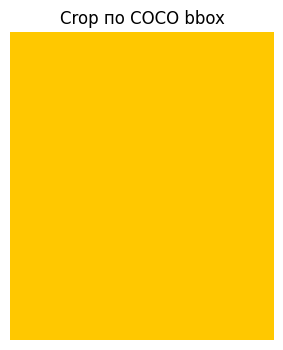

In [23]:
# Визуализируем:

plt.figure(figsize=(6, 4))
plt.imshow(cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB))
plt.title("Crop по COCO bbox")
plt.axis("off")
plt.show()


## 14. Предобработка изображения для модели

Обычно перед подачей в нейросеть изображение нужно:

1. Изменить размер.
2. Перевести из BGR в RGB.
3. Привести к типу `float32`.
4. Нормализовать.
5. Переставить оси из `HWC` в `CHW`.
6. Добавить батч-измерение.



In [44]:
def preprocess_bgr_for_onnx(image_bgr: np.ndarray, size: int = 224) -> np.ndarray:
    """
    Подготавливает изображение в формате BGR для подачи в ONNX-модель.
    Возвращает тензор вида (1, 3, H, W), float32.
    """

    # 1. Resize
    image = cv2.resize(image_bgr, (size, size))

    # 2. BGR -> RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # 3. Normalization
    image = image.astype(np.float32) / 255.0

    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    image = (image - mean) / std

    # 4. HWC -> CHW
    image = np.transpose(image, (2, 0, 1))

    # 5. Добавляем батч
    image = np.expand_dims(image, axis=0)

    return image



In [25]:
# Подготавливаем кроп:

input_crop = preprocess_bgr_for_onnx(crop_bgr, size=224)

print("Input shape:", input_crop.shape)
print("Input dtype:", input_crop.dtype)


Input shape: (1, 3, 224, 224)
Input dtype: float32


Ожидаемый вывод:

```text
Input shape: (1, 3, 224, 224)
Input dtype: float32
```

---

## 15. Инференс ONNX-модели на кропе



In [45]:
logits = session.run(None, {"input": input_crop})[0]

print("Raw logits:", logits)


Raw logits: [[-0.32334012 -0.13216391]]


In [46]:
# Получаем вероятности:

probs = torch.softmax(torch.from_numpy(logits), dim=1).numpy()

print("Probabilities:", probs)


Probabilities: [[0.45235094 0.54764897]]


Так как модель в примере не обучена, вероятности будут случайными. Это нормально. Главная цель — показать инфраструктуру.

---

## 16. Опционально: экспорт torchvision MobileNetV3 Small

Для более реалистичного примера можно взять лёгкую модель из `torchvision`.

```python
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
```

Загрузка весов:

```python
try:
    weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1
    mv3_model = mobilenet_v3_small(weights=weights).eval()
    class_names = weights.meta["categories"]
    print("Загружены предобученные веса MobileNetV3 Small.")
except Exception as e:
    print("Не удалось загрузить веса:", e)
    mv3_model = mobilenet_v3_small(weights=None).eval()
    class_names = None
```

Экспорт в ONNX:

```python
dummy_input = torch.randn(1, 3, 224, 224)

mv3_onnx_path = "mobilenetv3_small.onnx"

torch.onnx.export(
    mv3_model,
    dummy_input,
    mv3_onnx_path,
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["logits"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "logits": {0: "batch_size"}
    }
)

print("MobileNetV3 Small сохранён в", mv3_onnx_path)
```

Создаём сессию:

```python
mv3_session = ort.InferenceSession(mv3_onnx_path, providers=preferred_providers)
```

Запускаем на том же кропе:

```python
mv3_logits = mv3_session.run(None, {"input": input_crop})[0]
mv3_probs = torch.softmax(torch.from_numpy(mv3_logits), dim=1).numpy()[0]
```

Если веса загрузились, можно вывести топ-5 классов:

```python
if class_names is not None:
    top5_indices = np.argsort(mv3_probs)[-5:][::-1]
    
    print("Top-5 предсказаний:")
    for idx in top5_indices:
        print(f"{class_names[idx]:25s}: {mv3_probs[idx]:.4f}")
else:
    print("Предсказание со случайными весами:")
    print(mv3_probs[:10])
```

---

## 17. Как это связано с детекцией и форматами разметки?

В задачах детекции модель обычно возвращает:

- координаты рамок;
- уверенность;
- идентификаторы классов.

Если модель возвращает координаты в формате YOLO:

```text
class_id x_center y_center width height
```

и координаты нормализованы, то их можно конвертировать в COCO:

```python
def yolo_norm_to_coco(box_norm, img_width, img_height):
    """
    box_norm: [x_center, y_center, width, height], все значения в диапазоне [0, 1]
    Возвращает COCO-формат: [x_min, y_min, width, height]
    """
    
    x_center, y_center, w, h = box_norm
    
    x_min = (x_center - w / 2.0) * img_width
    y_min = (y_center - h / 2.0) * img_height
    w_abs = w * img_width
    h_abs = h * img_height
    
    return [float(x_min), float(y_min), float(w_abs), float(h_abs)]
```

Пример:

```python
img_w = 640
img_h = 480

# Пример нормализованного YOLO-box
yolo_box = [0.5, 0.5, 0.4, 0.6]

coco_box = yolo_norm_to_coco(yolo_box, img_w, img_h)

print("YOLO normalized:", yolo_box)
print("COCO bbox:", coco_box)
```

Ожидаемый вывод:

```text
YOLO normalized: [0.5, 0.5, 0.4, 0.6]
COCO bbox: [192.0, 96.0, 256.0, 288.0]
```

Это полезно, когда вы:

- обучили детектор;
- получили предсказания;
- хотите сохранить их в COCO для оценки через `pycocotools`;
- или хотите визуализировать результат.

---

## 18. Пример сохранения предсказания в COCO-подобный формат

Допустим, модель предсказала объект с нормализованным YOLO-боксом.

```python
prediction = {
    "image_id": 1,
    "category_id": 1,
    "score": 0.87,
    "bbox": yolo_norm_to_coco([0.5, 0.5, 0.4, 0.6], 640, 480)
}

print(json.dumps(prediction, indent=4))
```

Результат:

```json
{
    "image_id": 1,
    "category_id": 1,
    "score": 0.87,
    "bbox": [
        192.0,
        96.0,
        256.0,
        288.0
    ]
}
```

Такой формат уже близок к COCO detection results.

---

## 19. Добавление метаданных в ONNX-модель

Иногда полезно сохранить служебную информацию прямо в модели:

- имена классов;
- тип нормализации;
- версию датасета;
- формат аннотаций;
- версию обучения.

Пример:

```python
model_with_meta = onnx.load("tiny_cnn.onnx")

meta = model_with_meta.metadata_props.add()
meta.key = "class_names"
meta.value = json.dumps(["background", "object"])

meta2 = model_with_meta.metadata_props.add()
meta2.key = "annotation_format"
meta2.value = "COCO-like"

onnx.save(model_with_meta, "tiny_cnn_with_meta.onnx")

print("Метаданные добавлены и сохранены в tiny_cnn_with_meta.onnx")
```

Проверка:

```python
loaded_meta_model = onnx.load("tiny_cnn_with_meta.onnx")

for prop in loaded_meta_model.metadata_props:
    print(prop.key, "=", prop.value)
```

---

## 20. Частые ошибки при работе с ONNX

### Ошибка 1: Несовпадение имени входа

Пример:

```python
session.run(None, {"x": input_tensor})
```

Но модель ожидает:

```python
{"input": input_tensor}
```

Проверяйте имена так:

```python
print(session.get_inputs())
```

---

### Ошибка 2: Неправильный порядок осей

Частые ошибки:

```text
Ожидается: NCHW
Подано: NHWC
```

Для PyTorch и большинства CV-моделей:

```text
N - batch
C - channels
H - height
W - width
```

То есть:

```python
image = image.transpose(2, 0, 1)
```

---

### Ошибка 3: Забытая нормализация

Если модель обучалась с:

```python
transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
```

то при инференсе нужно применить ту же нормализацию.

---

### Ошибка 4: Модель в режиме обучения

Перед экспортом:

```python
model.eval()
```

Иначе `Dropout`, `BatchNorm` и другие слои могут вести себя иначе.

---

### Ошибка 5: Неподдерживаемая операция

Не все PyTorch-операции идеально экспортируются в ONNX.

Типичные проблемные места:

- сложная динамическая логика;
- кастомные слои;
- нестандартные постобработки;
- динамические циклы;
- некоторые операции обработки изображений.

Решения:

- упростить модель;
- вынести постобработку из модели;
- обновить `opset_version`;
- использовать кастомные ONNX-операторы;
- переписать часть логики на этапе инференса.

---

## 21. Краткая схема полного пайплайна

```text
1. Разметка данных
   COCO / YOLO / VOC
        ↓
2. Парсинг аннотаций
   получение bbox, классов, размеров
        ↓
3. Подготовка изображений
   crop, resize, color conversion, normalization
        ↓
4. Экспорт модели
   PyTorch → ONNX
        ↓
5. Инференс
   ONNX Runtime
        ↓
6. Постобработка
   приведение предсказаний к COCO/YOLO/VOC
        ↓
7. Оценка качества
   pycocotools, mAP, IoU
```

---

# 22. Задания для самостоятельной работы

## Базовое задание по теме лекции

### Задание 1. Чтение COCO JSON

Напишите скрипт, который:

1. Читает тестовый JSON-файл в формате COCO.
2. Выводит список изображений.
3. Выводит список категорий.
4. Выводит все аннотации для одного изображения.

Подсказка:

```python
with open("annotations.json", "r") as f:
    coco = json.load(f)
```

---

### Задание 2. Конвертер COCO → YOLO для одного класса

Реализуйте конвертер, который:

1. Читает COCO JSON.
2. Выбирает аннотации только для заданного класса, например `"dog"`.
3. Нормализует координаты относительно ширины и высоты изображения.
4. Сохраняет результат в текстовый файл в формате YOLO.

Формат строки YOLO:

```text
class_id x_center y_center width height
```

Подсказка по формулам:

```python
x_center = (x_min + width / 2) / image_width
y_center = (y_min + height / 2) / image_height
norm_width = width / image_width
norm_height = height / image_height
```

---

### Задание 3. Экспорт модели в ONNX

Возьмите любую небольшую PyTorch-модель и:

1. Экспортируйте её в ONNX.
2. Загрузите через `onnxruntime`.
3. Подайте случайный вход.
4. Сравните результат с PyTorch.
5. Сделайте вывод, совпадают ли предсказания.

---

## Дополнительные задания повышенной сложности

### Задание 4. Кроп по COCO + ONNX-инференс

Соберите полный пайплайн:

1. Создайте или загрузите изображение.
2. Создайте или загрузите COCO-аннотацию.
3. Вырежьте объект по `bbox`.
4. Сделайте предобработку.
5. Запустите ONNX-модель.
6. Сохраните результат в JSON:

```json
{
    "image_id": 1,
    "bbox": [x_min, y_min, width, height],
    "predicted_class": 0,
    "probability": 0.72
}
```

Подсказка:

```python
predicted_class = int(np.argmax(probs, axis=1)[0])
probability = float(np.max(probs))
```

---

### Задание 5. Конвертация предсказаний YOLO → COCO

Представьте, что ONNX-детектор вернул нормализованные YOLO-боксы.

Напишите функцию, которая:

1. Принимает массив предсказаний:

```python
predictions = [
    [class_id, x_center, y_center, width, height, score],
    ...
]
```

2. Принимает размеры изображения.
3. Конвертирует каждый бокс в COCO-формат.
4. Возвращает список словарей для COCO evaluation.

Пример результата:

```python
[
    {
        "image_id": 1,
        "category_id": 1,
        "bbox": [x_min, y_min, width, height],
        "score": 0.92
    }
]
```

---

### Задание 6. Сравнение скорости PyTorch и ONNX Runtime

Возьмите экспортированную ONNX-модель и сравните:

- инференс исходной PyTorch-модели;
- инференс через ONNX Runtime.

Измерьте среднее время на 100 запусков.

Каркас функции:

```python
def benchmark_function(func, n_runs=100, warmup=10):
    # warmup
    for _ in range(warmup):
        func()
    
    start = time.perf_counter()
    
    for _ in range(n_runs):
        func()
    
    end = time.perf_counter()
    
    avg_time = (end - start) / n_runs
    return avg_time * 1000  # миллисекунды
```

Подсказка:

```python
def run_torch():
    with torch.no_grad():
        model(torch_input)

def run_onnx():
    session.run(None, {"input": np_input})
```

---

## 23. Контрольные вопросы для самопроверки

1. Что такое ONNX и зачем он нужен в компьютерном зрении?
2. Чем `.pt`/`.pth` отличается от `.onnx`?
3. Что такое `opset_version`?
4. Зачем нужны `dynamic_axes`?
5. Какой формат координат использует COCO?
6. Какой формат координат использует YOLO?
7. Как перевести `x_min, y_min, width, height` в `x_center, y_center, width, height`?
8. Почему при экспорте модели нужно вызывать `model.eval()`?
9. Почему важно совпадение нормализации при обучении и инференсе?
10. Какие проблемы могут возникнуть при экспорте детекторов в ONNX?

---

## 24. Краткий конспект

- **Аннотации** описывают, какие объекты есть на изображении.
- **COCO** хранит всё в одном JSON и использует абсолютные координаты `[x, y, w, h]`.
- **YOLO** хранит нормализованные координаты `[class_id, x_center, y_center, width, height]`.
- **ONNX** — универсальный формат модели для инференса.
- **PyTorch → ONNX** выполняется через `torch.onnx.export`.
- **ONNX Runtime** позволяет запускать модель без прямого использования исходного кода модели.
- В реальных проектах часто нужно конвертировать не только разметку, но и предсказания модели обратно в нужный формат, например, в COCO.

---